# Data Understanding for the microbiology events dastaset

In [85]:
import pandas as pd
import numpy as np
import sys
import os
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))

from src.utils import data_understanding as du

lab_events_df = pd.read_csv("../../data/raw/microbiology_events_codes_3.csv")

## General info about the data set

This section contains some general and basic informations about the dataset

In [86]:
# Shape of the dataset (rows, columns)
rows,columns = lab_events_df.shape
print(f"Rows: {rows}, Cols: {columns}")


Rows: 15587, Cols: 14


In [87]:
# Info about the dataframe
du.get_info(lab_events_df)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15587 entries, 0 to 15586
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   subject_id           15587 non-null  int64  
 1   hadm_id              15587 non-null  float64
 2   chartdate            15587 non-null  object 
 3   charttime            15587 non-null  object 
 4   spec_type_desc       15587 non-null  object 
 5   test_name            15587 non-null  object 
 6   org_name             5391 non-null   object 
 7   ab_name              4820 non-null   object 
 8   dilution_text        4713 non-null   object 
 9   dilution_comparison  4711 non-null   object 
 10  dilution_value       4711 non-null   float64
 11  interpretation       4820 non-null   object 
 12  technician_id        15587 non-null  object 
 13  qc_flag              15587 non-null  object 
dtypes: float64(2), int64(1), object(11)
memory usage: 1.7+ MB


In [ ]:
numeric_cols = du.get_numeric_cols(lab_events_df)

,subject_id,hadm_id,dilution_value
count,1.558700e+04,1.558700e+04,4711.000000
mean,1.522098e+07,2.503469e+07,7.062420
std,2.910238e+06,2.846364e+06,21.245298
min,1.000098e+07,2.000790e+07,0.060000
25%,1.266277e+07,2.266346e+07,0.500000
50%,1.519823e+07,2.514649e+07,1.000000
75%,1.772189e+07,2.743116e+07,4.000000
max,1.999767e+07,2.999967e+07,512.000000


In [89]:
# Column names presents in the dataset
cols = du.get_cols(lab_events_df)
print(cols)

['subject_id', 'hadm_id', 'chartdate', 'charttime', 'spec_type_desc', 'test_name', 'org_name', 'ab_name', 'dilution_text', 'dilution_comparison', 'dilution_value', 'interpretation', 'technician_id', 'qc_flag']


In [90]:
def get_percentage_cols_with_none(df):
    cols_with_none_info = du.get_cols_with_none(df)
    n_cols_with_none = np.count_nonzero(cols_with_none_info % 2 == 1)

    percentage_of_cols_with_none = (n_cols_with_none / len(du.get_cols(df))) * 100

    return percentage_of_cols_with_none
# Getting the percentage of columns with at least one None
print(f"Percentage of columns with at least one None value in the dataframe: {get_percentage_cols_with_none(lab_events_df):.2f} %")

Percentage of columns with at least one None value in the dataframe: 42.86 %


In [91]:
def get_none_percentage_per_cols(df):
    res = []
    for col in cols:
        not_none = (lab_events_df[col].count())
        none_percentage = ((rows - not_none)/rows)*100
        res.append((col, none_percentage))
    return res
# Get the percentage of None values for each columns
none_percentage_per_cols = []

print("=== PERCENTAGE OF NONE PER COLUMN ===")
for col, percentage in get_none_percentage_per_cols(lab_events_df):
    print(f"{col}: {percentage:.2f}%")

=== PERCENTAGE OF NONE PER COLUMN ===
subject_id: 0.00%
hadm_id: 0.00%
chartdate: 0.00%
charttime: 0.00%
spec_type_desc: 0.00%
test_name: 0.00%
org_name: 65.41%
ab_name: 69.08%
dilution_text: 69.76%
dilution_comparison: 69.78%
dilution_value: 69.78%
interpretation: 69.08%
technician_id: 0.00%
qc_flag: 0.00%


## Distribution plots

### Quality flag distribution plot

<Axes: xlabel='qc_flag', ylabel='Count'>

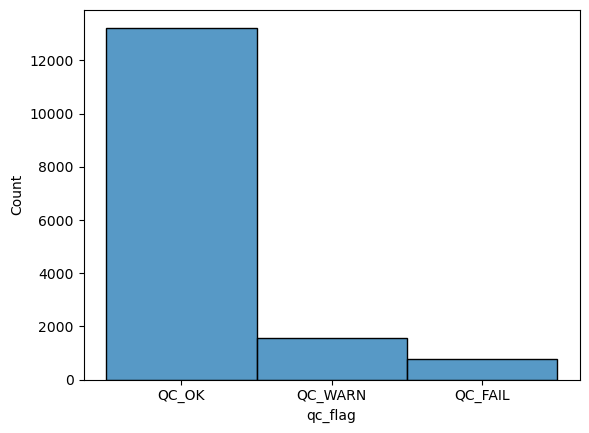

In [92]:
sns.histplot(data=lab_events_df, x='qc_flag')

### Organism name distribution plot

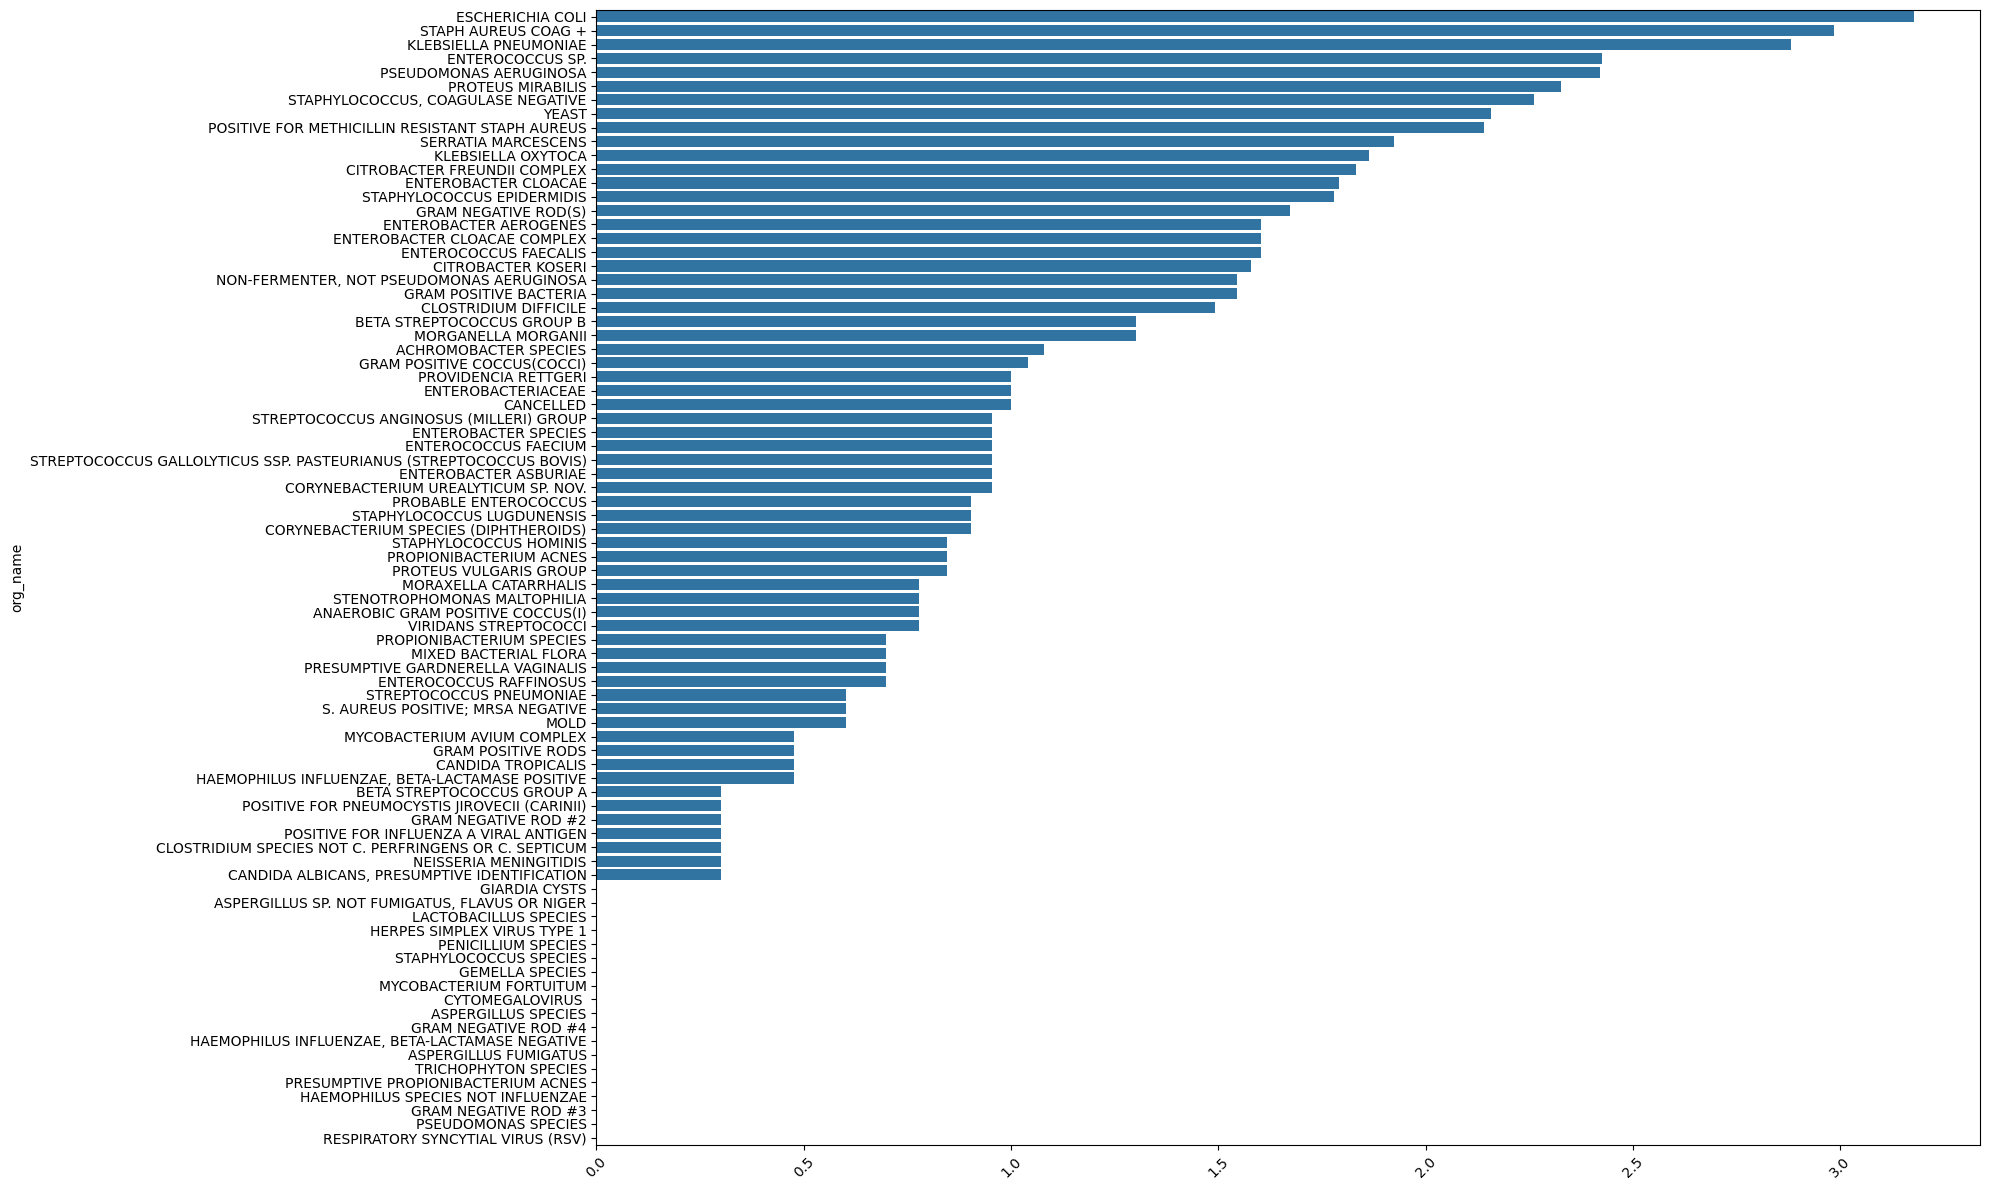

In [93]:
org_count = np.log10(lab_events_df['org_name'].value_counts())

plt.figure(figsize=(20, 12))
sns.barplot(y=org_count.index, x=org_count.values)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Test distribution plot

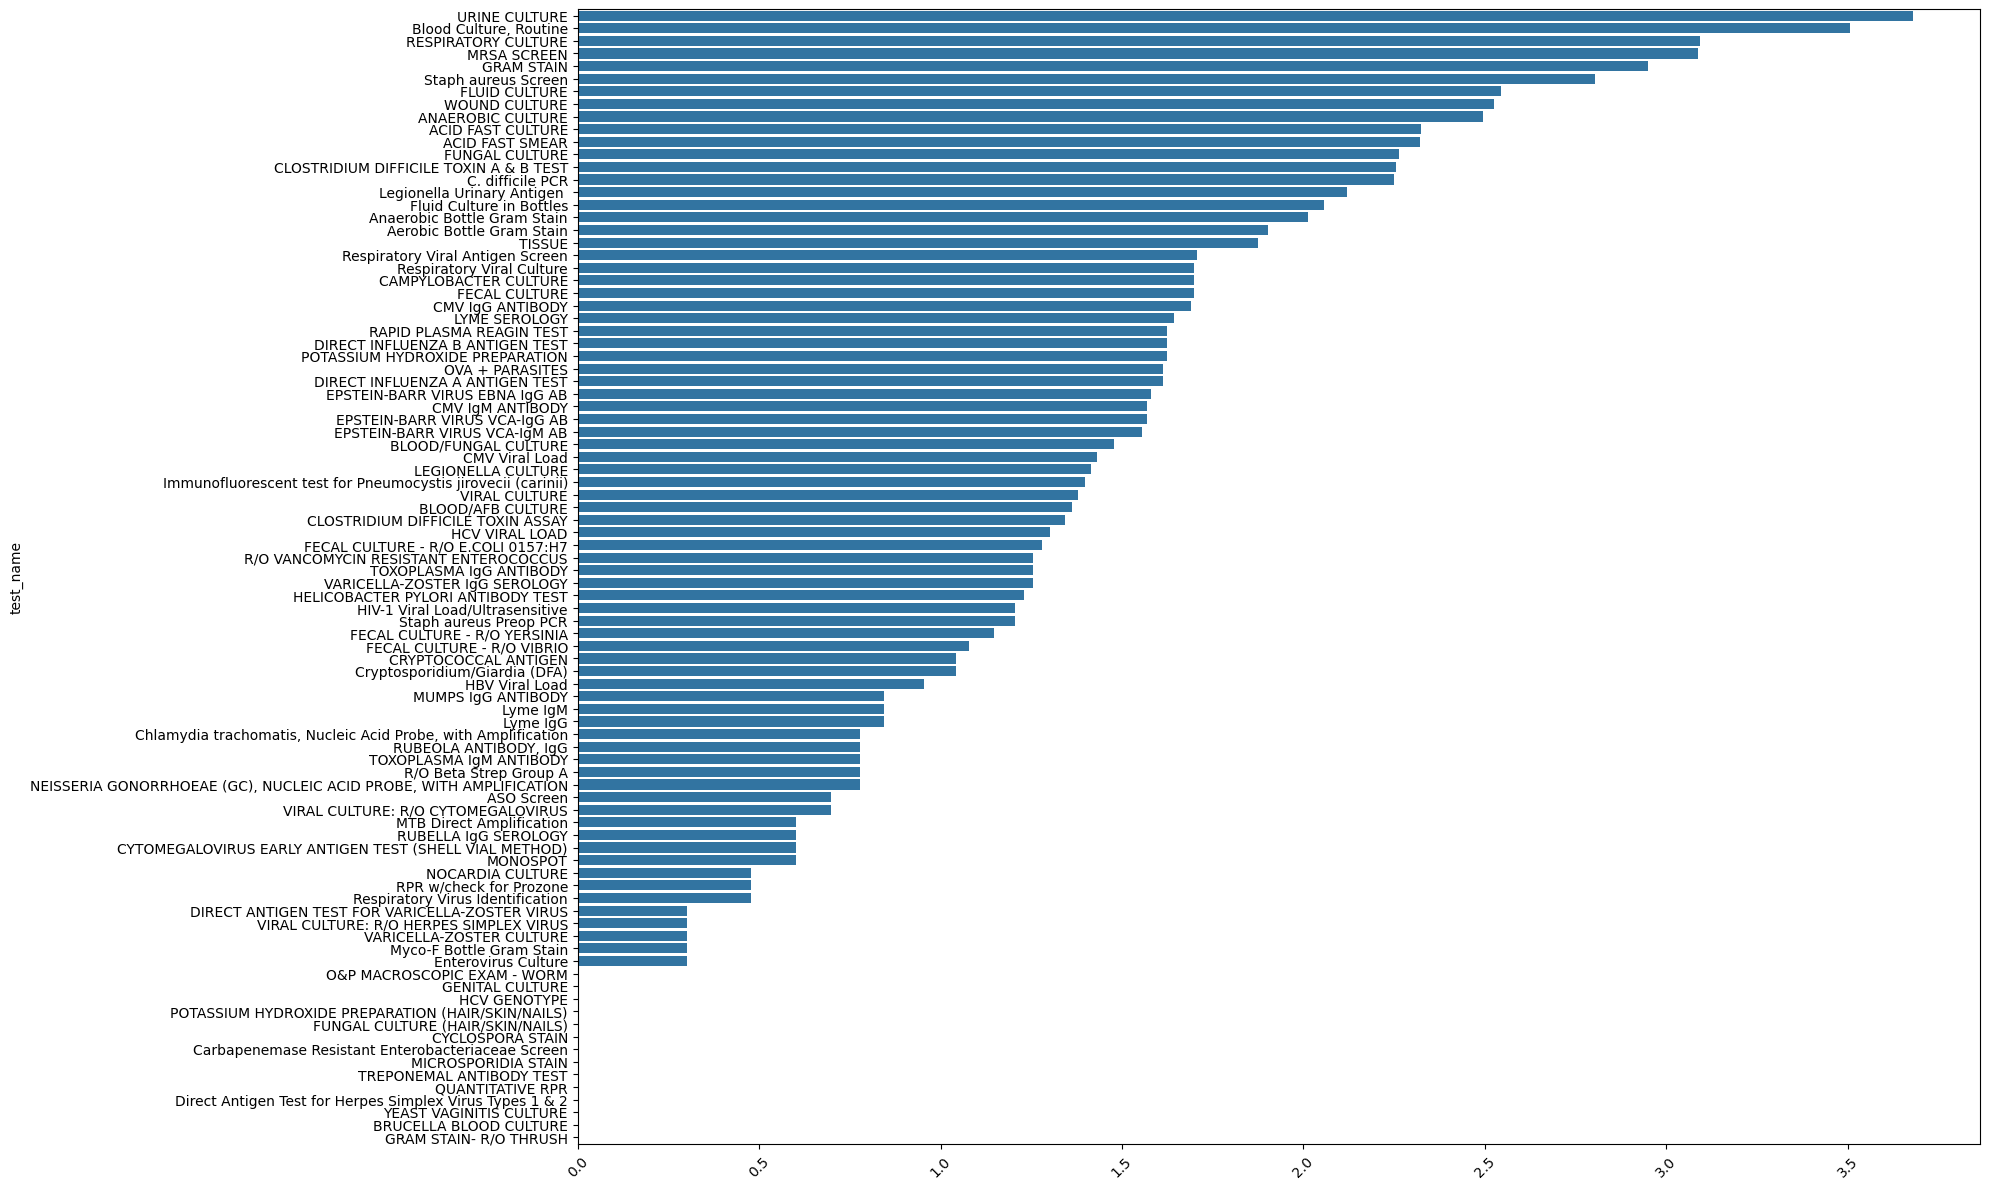

In [94]:
test_count = np.log10(lab_events_df['test_name'].value_counts())

plt.figure(figsize=(20, 12))
sns.barplot(y=test_count.index, x=test_count.values)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

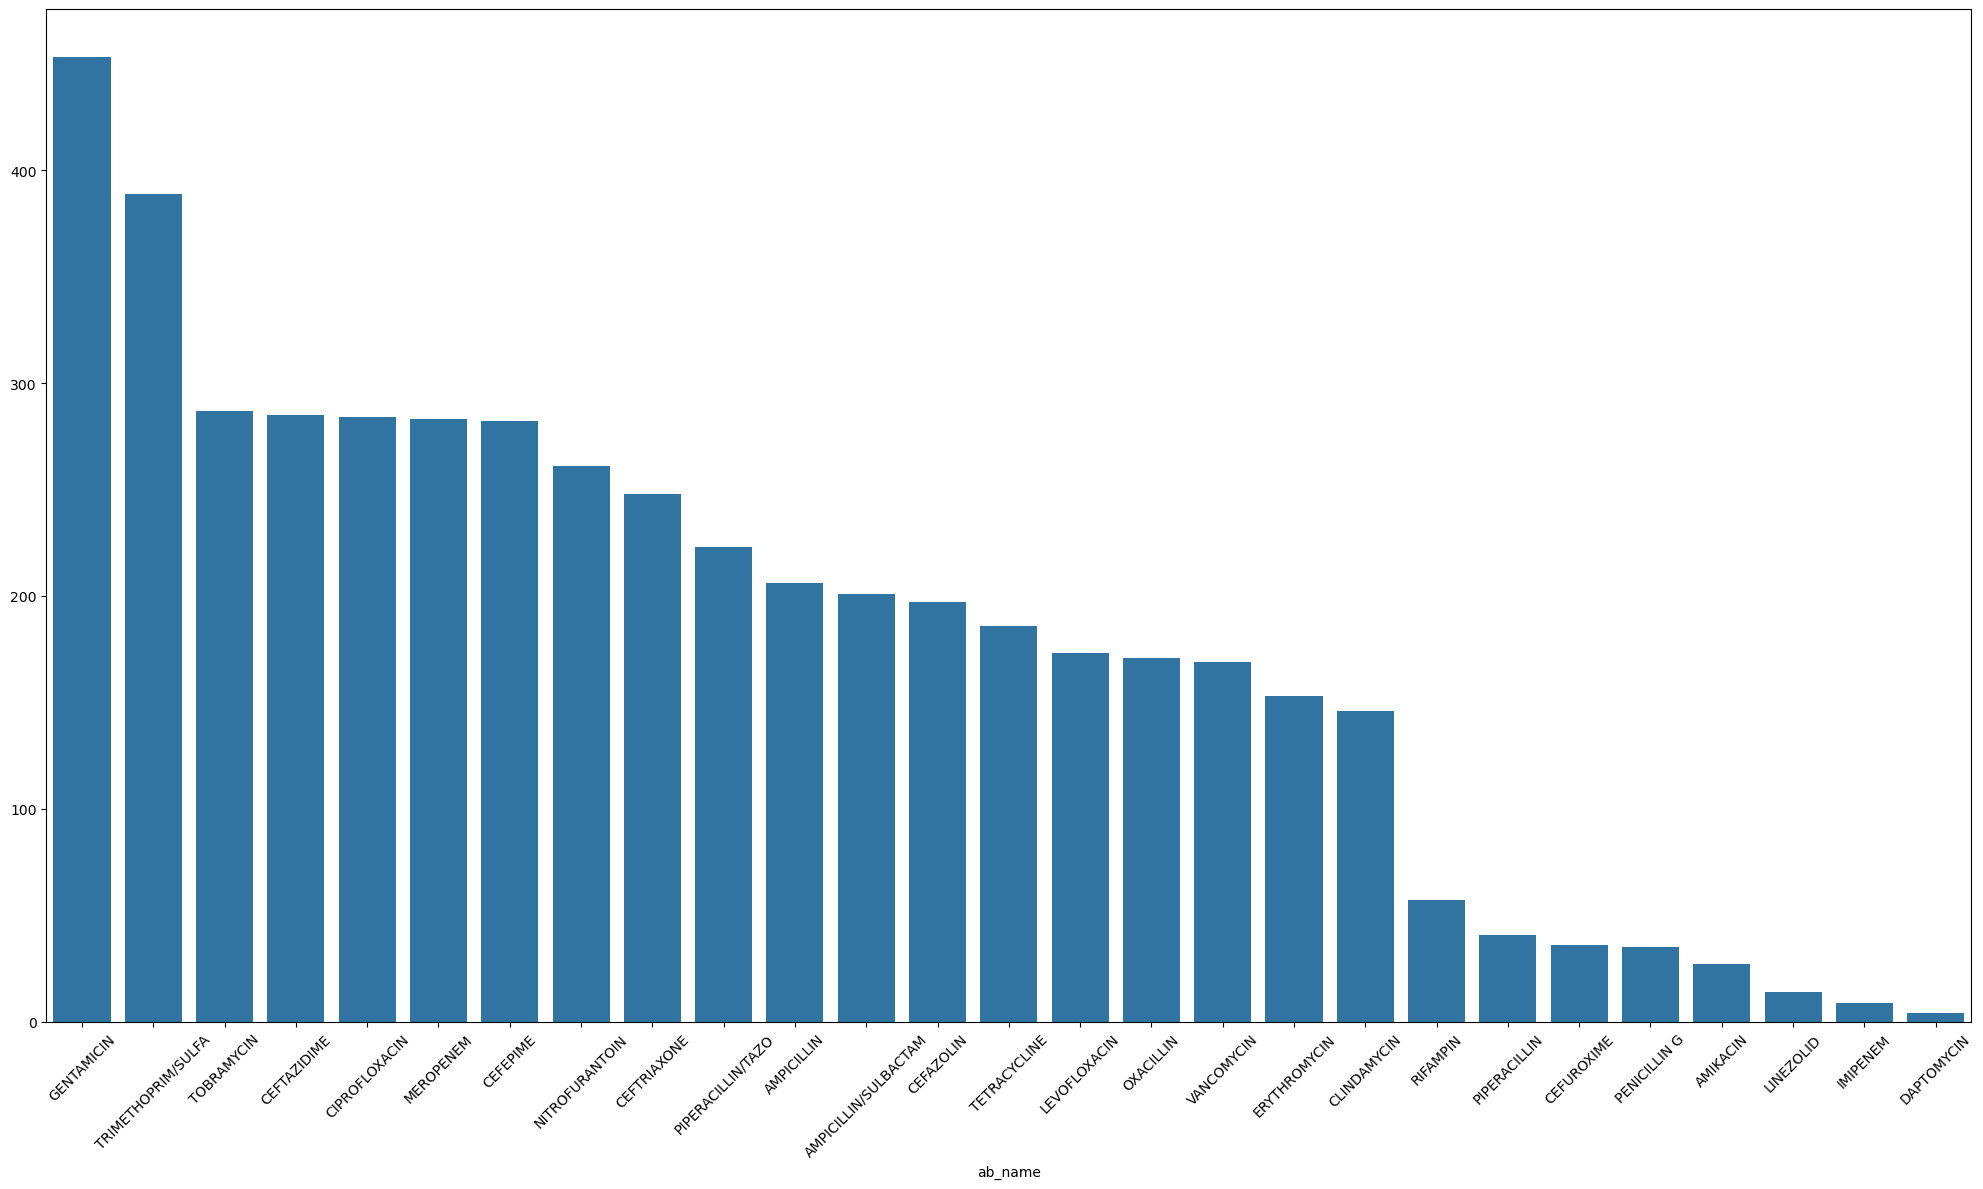

In [95]:
ab_count = lab_events_df['ab_name'].value_counts()

plt.figure(figsize=(20, 12))
sns.barplot(x=ab_count.index, y=ab_count.values)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

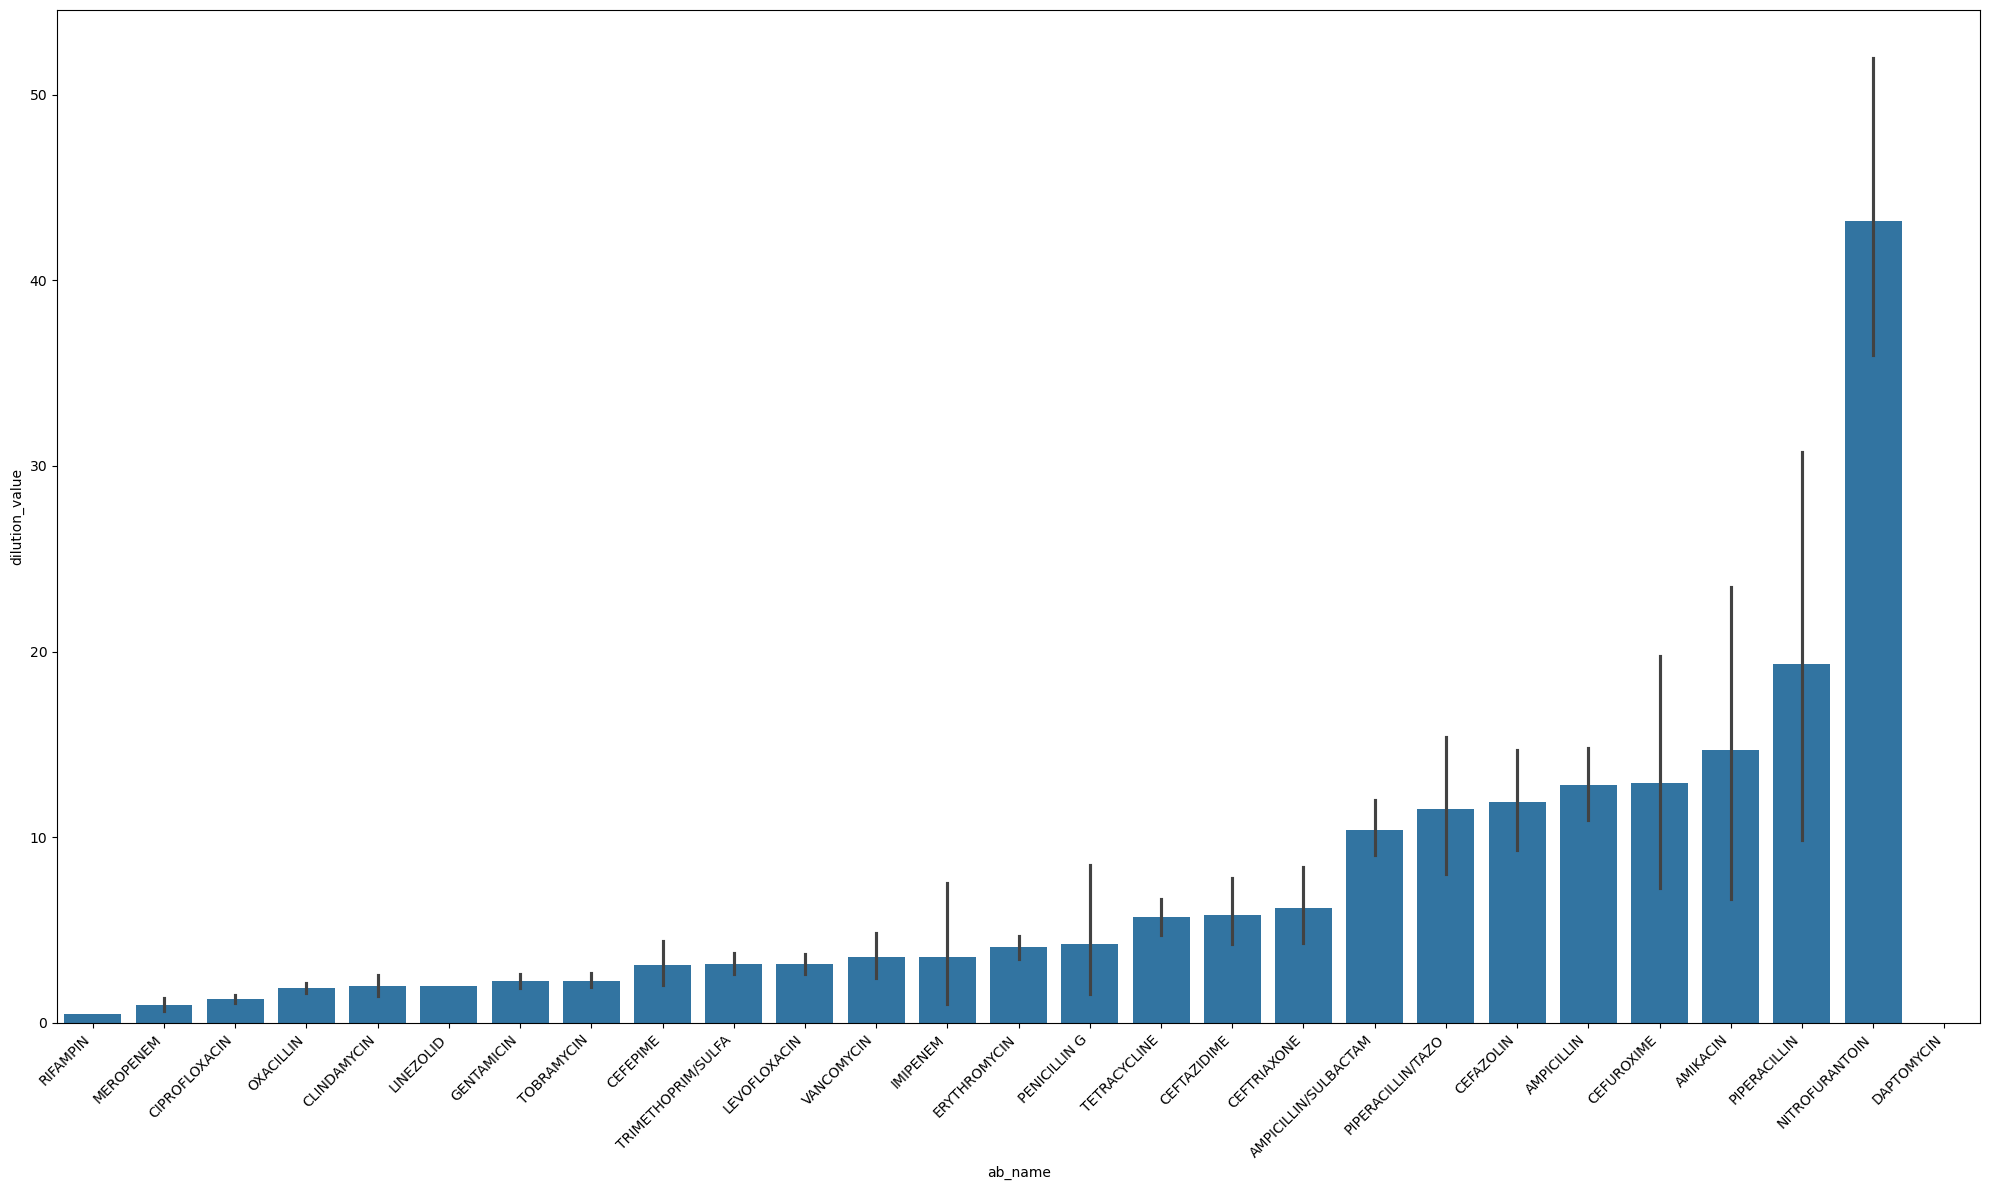

In [96]:
order = lab_events_df.groupby('ab_name')['dilution_value'].mean().sort_values().index

plt.figure(figsize=(20, 12))
sns.barplot(data=lab_events_df, x='ab_name', y='dilution_value', order=order)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()